In [15]:
#cell 1
import json, random, re, unicodedata, zlib
from collections import Counter

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import pyiwn

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

CFG = dict(
    window=5,                  # context words kept on each side of the target
    n_buckets=2**12,           # hashed feature space (no vocabulary file to save)
    ngram_min=3, ngram_max=4,  # character n-gram sizes (robust to Kannada suffixes)
    max_ctx_feats=256, max_gloss_feats=256,
    emb_dim=32, hidden=32, dropout=0.5,
    max_candidates=12,         # senses per word allowed in training batches
)

# ---------------- Run configuration (replaces Colab's upload / download widgets) ----------------
import sys
from pathlib import Path

# Path to your CSV (columns: "Kannada Sentence", "Target Word", "Lemmatized Target Word").
# Override from the command line:  python finalwsdproject.py my_file.csv
CSV_PATH = r"C:\Users\HP\OneDrive\Desktop\collage_projects\WSD_kannada\lemmatized_kannada_words.csv"

# Optional: your hand-annotated copy of annotation_template.csv (with "Gold Sense ID" filled in).
# Leave as None to skip the evaluation step.
GOLD_PATH = r"C:\Users\HP\OneDrive\Desktop\collage_projects\WSD_kannada\gold_senseID.csv"

# Optional extras - switch on as needed.
EXPORT_ANNOTATION_TEMPLATE = True   # writes annotation_template.csv
ASK_INTERACTIVELY = True           # prompts in the terminal for a sentence / word
LAUNCH_GRADIO = True               # starts the web UI (needs `pip install gradio`)

OUT_DIR = Path(".")    


In [17]:
#cell 2
def clean(text):
    """Unicode NFC + remove zero-width characters, so equal-looking strings compare equal."""
    text = unicodedata.normalize("NFC", str(text))
    return re.sub("[\u200b\u200c\u200d]", "", text).strip()

df = pd.read_csv(CSV_PATH, encoding="utf-8")
REQUIRED = ["Kannada Sentence", "Target Word", "Lemmatized Target Word"]
missing = [c for c in REQUIRED if c not in df.columns]
assert not missing, f"Missing columns {missing}; found {list(df.columns)}"

n_before = len(df)
df = df.dropna(subset=REQUIRED).reset_index(drop=True)
for c in REQUIRED:
    df[c] = df[c].map(clean)
print(f"{len(df)} usable rows ({n_before - len(df)} dropped for empty cells)")
df[REQUIRED].head()

40 usable rows (0 dropped for empty cells)


,Kannada Sentence,Target Word,Lemmatized Target Word
0,ಕಾಡುಗಳನ್ನು ನಾಶಪಡಿಸಲಾಗುತ್ತಿದೆ.,ಕಾಡು,ಕಾಡು
1,"ಮನುಷ್ಯರಿಲ್ಲದೆ ಸಸ್ಯಗಳೂ, ಪ್ರಾಣಿಗಳು ಇರಬಲ್ಲವು, ಆದರ...",ನೆರವು,ನೆರವು
2,ಕೀಟನಾಶಕಗಳನ್ನು ಅತಿಯಾಗಿ ಬಳಸದೆ ಬೆಳೆದ ಆಹಾರವನ್ನು ಆಯ...,ಬೆಳೆದ,ಬೆಳೆ
3,ಸೂಕ್ತ ತಾಂತ್ರಿಕ ಪ್ರಕ್ರಿಯೆಗಳನ್ನು ಮತ್ತು ಸಂಪನ್ಮೂಲಗ...,ರಚಿಸುವುದು,ರಚಿಸು
4,ಈ ಹಲವಾರು ಪದಗಳಲ್ಲಿ ಪ್ರತಿಯೊಂದು ಅದರ ಸಮರ್ಥಕರನ್ನು ಹ...,ಪದ,ಪದ


In [19]:
#cell 3
TOKEN_RE = re.compile(r"[\u0C80-\u0CFF]+|[A-Za-z0-9]+")

def tokenize(text):
    return TOKEN_RE.findall(clean(text))

df["tokens"] = df["Kannada Sentence"].map(tokenize)
df[["Kannada Sentence", "tokens"]].head(3)

,Kannada Sentence,tokens
0,ಕಾಡುಗಳನ್ನು ನಾಶಪಡಿಸಲಾಗುತ್ತಿದೆ.,"[ಕಾಡುಗಳನ್ನು, ನಾಶಪಡಿಸಲಾಗುತ್ತಿದೆ]"
1,"ಮನುಷ್ಯರಿಲ್ಲದೆ ಸಸ್ಯಗಳೂ, ಪ್ರಾಣಿಗಳು ಇರಬಲ್ಲವು, ಆದರ...","[ಮನುಷ್ಯರಿಲ್ಲದೆ, ಸಸ್ಯಗಳೂ, ಪ್ರಾಣಿಗಳು, ಇರಬಲ್ಲವು, ..."
2,ಕೀಟನಾಶಕಗಳನ್ನು ಅತಿಯಾಗಿ ಬಳಸದೆ ಬೆಳೆದ ಆಹಾರವನ್ನು ಆಯ...,"[ಕೀಟನಾಶಕಗಳನ್ನು, ಅತಿಯಾಗಿ, ಬಳಸದೆ, ಬೆಳೆದ, ಆಹಾರವನ್..."


In [21]:
#cell 4
import builtins
orig_open = builtins.open
def utf8_open(*args, **kwargs):
    if 'encoding' not in kwargs:
        kwargs['encoding'] = 'utf-8'
    return orig_open(*args, **kwargs)

builtins.open = utf8_open

import pyiwn
pyiwn.download()
iwn = pyiwn.IndoWordNet(pyiwn.Language.KANNADA)

SYNSETS = list(iwn.all_synsets())
for m in ("gloss", "examples", "lemma_names", "pos", "synset_id"):
    assert hasattr(SYNSETS[0], m), f"This pyiwn version has no Synset.{m}()"
sample = next(s for s in SYNSETS if s.examples())
assert isinstance(sample.examples(), (list, tuple)), f"examples() returned {type(sample.examples())}"

LEMMA_RAW = {clean(l): l for s in SYNSETS for l in s.lemma_names()}   # cleaned lemma -> original string
LEMMA_VOCAB = set(LEMMA_RAW)
print(f"{len(SYNSETS)} synsets | {len(LEMMA_VOCAB)} lemmas | {sum(1 for s in SYNSETS if s.examples())} synsets with example sentences")

_syn_cache = {}
def get_synsets(lemma):
    """Candidate senses of a lemma, in IndoWordNet order, de-duplicated. [] if the lemma is not in IndoWordNet."""
    if lemma not in LEMMA_VOCAB:
        return []
    if lemma not in _syn_cache:
        seen, out = set(), []
        for s in iwn.synsets(LEMMA_RAW[lemma]):
            if s.synset_id() not in seen:
                seen.add(s.synset_id()); out.append(s)
        _syn_cache[lemma] = out
    return _syn_cache[lemma]

2026-11-04:10:19:22,893 INFO     [iwn.py:43] Loading kannada language synsets...


22042 synsets | 61677 lemmas | 22042 synsets with example sentences


In [23]:
#cell 5
DEP_VOWELS = set("ಾಿೀುೂೃೆೇೈೊೋೌ")           # dependent vowel signs
NON_STARTERS = DEP_VOWELS | set("್ಂಃ")        # characters that cannot begin an akshara

class IWNLemmatizer:
    def __init__(self, vocab, min_len=2):
        self.vocab, self.min_len, self._cache = vocab, min_len, {}

    def __call__(self, tok):
        """-> (lemma, found_in_wordnet)"""
        if tok not in self._cache:
            self._cache[tok] = self._lookup(tok)
        return self._cache[tok]

    def _lookup(self, tok):
        for end in range(len(tok), self.min_len - 1, -1):
            stem, nxt = tok[:end], tok[end:end + 1]
            if stem[-1] == "್" or nxt in ("್", "ಂ", "ಃ"):      # cut would fall inside an akshara
                continue
            options = [stem] + ([stem + "ು"] if nxt in DEP_VOWELS else [])   # ಊರ|ಿಗೆ -> ಊರು
            for cand in options:
                if cand in self.vocab:
                    return cand, True
        return tok, False

lem = IWNLemmatizer(LEMMA_VOCAB)

# --- validation against YOUR gold lemma column ---
pred = df["Target Word"].map(lambda w: lem(w)[0])
ok = pred == df["Lemmatized Target Word"]
print(f"Automatic lemma == gold lemma for {ok.mean():.1%} of {len(df)} target words")
df.loc[~ok, ["Target Word", "Lemmatized Target Word"]].assign(predicted=pred[~ok]).head(15)

Automatic lemma == gold lemma for 92.5% of 40 target words


,Target Word,Lemmatized Target Word,predicted
3,ರಚಿಸುವುದು,ರಚಿಸು,ರಚಿಸುವುದು
17,ಬಣ್ಣಿಸಿದ್ದಾರೆ,ಬಣ್ಣಿಸು,ಬಣ್ಣ
24,ಕಲ್ಪಿಸಬಹುದು,ಕಲ್ಪಿಸು,ಕಲ್ಪಿಸಬಹುದು


In [25]:
#cell 6
def prefix_match(tok, lemma):
    """True if tok starts with the lemma stem and the cut does not fall inside an akshara."""
    ends_u = lemma.endswith("ು")
    stem = lemma[:-1] if ends_u else lemma
    if len(stem) < 2 or not tok.startswith(stem):
        return False
    rest = tok[len(stem):]
    if rest and rest[0] in NON_STARTERS:
        return ends_u and rest[0] in DEP_VOWELS     # ನೆರವು ~ ನೆರವಿನ
    return True

def find_target(tokens, target, lemma):
    for i, t in enumerate(tokens):
        if t == target: return i, "surface"
    for i, t in enumerate(tokens):
        if lem(t)[0] == lemma: return i, "lemmatizer"
    for i, t in enumerate(tokens):
        if prefix_match(t, lemma): return i, "prefix"
    return None, "not_found"

def window(tokens, i, w):
    return tokens[max(0, i - w):i], tokens[i + 1:i + 1 + w]

found = [find_target(t, w, l) for t, w, l in zip(df["tokens"], df["Target Word"], df["Lemmatized Target Word"])]
df["target_idx"] = pd.array([f[0] for f in found], dtype="Int64")
df["locate_method"] = [f[1] for f in found]
located = df["target_idx"].notna()
df["left_ctx"] = [window(t, int(i), CFG["window"])[0] if ok_ else [] for t, i, ok_ in zip(df["tokens"], df["target_idx"].fillna(0), located)]
df["right_ctx"] = [window(t, int(i), CFG["window"])[1] if ok_ else [] for t, i, ok_ in zip(df["tokens"], df["target_idx"].fillna(0), located)]

print(df["locate_method"].value_counts().to_string())
print("\nRows where the target was NOT found (inspect these – typo, multi-word target, or unusual inflection):")
df.loc[~located, ["Kannada Sentence", "Target Word", "Lemmatized Target Word"]]

locate_method
lemmatizer    18
surface       16
prefix         5
not_found      1

Rows where the target was NOT found (inspect these – typo, multi-word target, or unusual inflection):


,Kannada Sentence,Target Word,Lemmatized Target Word
5,"ಪ್ರಾಯೋಗಿಕವಾಗಿ, ತಂತ್ರಜ್ಞಾನ ಮುಂದುವರೆದಂತೆ, ಆರಂಭದಲ...",ಅಂಶ,ಅಂಶ


In [27]:
#cell 7
df["n_senses"] = df["Lemmatized Target Word"].map(lambda l: len(get_synsets(l)))
print(df["n_senses"].value_counts().sort_index().to_string())

demo = df[(df["n_senses"] >= 2) & located].iloc[0]
print("\nSentence :", demo["Kannada Sentence"])
print("Target   :", demo["Target Word"], "| lemma:", demo["Lemmatized Target Word"])
print("Context  :", demo["left_ctx"], "<TARGET>", demo["right_ctx"])
for s in get_synsets(demo["Lemmatized Target Word"]):
    print(f"  [{s.synset_id()}] ({s.pos()}) {s.gloss()}")

n_senses
0     3
1     3
2     1
3     6
4     5
5     5
6     4
7     3
8     1
9     3
10    3
11    1
12    1
15    1

Sentence : ಕಾಡುಗಳನ್ನು ನಾಶಪಡಿಸಲಾಗುತ್ತಿದೆ.
Target   : ಕಾಡು | lemma: ಕಾಡು
Context  : [] <TARGET> ['ನಾಶಪಡಿಸಲಾಗುತ್ತಿದೆ']
  [2551] (noun) ಒಂದು ಸ್ಥಳದಿಂದ ತುಂಬಾ ದೂರದವರೆಗೂ ಮರ-ಗಿಡ, ಪೊದೆ ಮುಂತಾದವುಗಳು ತನ್ನಷ್ಟಕ್ಕೆ ತಾನೆ ಬೆಳೆಯುವುದು
  [2552] (adjective) ಕೃಷಿಮಾಡಿ ಬೆಳೆಸಿಲ್ಲದ, ನಿಸರ್ಗದ ಸಹಜ ಸ್ಥಿತಿಯಲ್ಲಿರುವ ಕಾಡು
  [5442] (noun) ಬೇಟೆಯಾಡುವ  ಸ್ಥಳ
  [7946] (adjective) ಕಾಡಿನಲ್ಲಿರುವ ಅಥವಾ ಕಾಡಿನಲ್ಲಿ ಸಿಗುವ
  [28034] (noun) ದೊಡ್ಡ ಮತ್ತು ದಡ್ಡವಾದ ಕಾಡುಗಳ ಕ್ಷೇತ್ರದಲ್ಲಿರುವ ಮರ-ಗಿಡ ಅಥವಾ ಬೇರೆ ವನಸ್ಪತಿಗಳು


In [29]:
#cell 8
def stable_hash(s, n_buckets):
    return 1 + zlib.crc32(s.encode("utf-8")) % (n_buckets - 1)      # 0 is reserved for padding

def word_feats(tok):
    lemma, in_wn = lem(tok)
    feats = ["w=" + tok]
    if in_wn and lemma != tok:
        feats.append("l=" + lemma)
    padded = f"<{tok}>"
    for n in range(CFG["ngram_min"], CFG["ngram_max"] + 1):
        feats += [padded[i:i + n] for i in range(len(padded) - n + 1)]
    return feats

def ctx_features(left, right):
    feats = []
    if left:  feats.append("L1=" + left[-1])      # immediate neighbours get their own features
    if right: feats.append("R1=" + right[0])
    for tok in left + right:
        feats += word_feats(tok)
    return feats

def gloss_features(syn):
    """Candidate-sense text = gloss + synonyms. Example sentences are deliberately NOT included (they are the training contexts)."""
    toks = tokenize(syn.gloss()) + [t for l in syn.lemma_names() for t in tokenize(l)]
    feats = []
    for t in toks:
        feats += word_feats(t)
    return feats

def encode(feats, max_len):
    ids = [stable_hash(f, CFG["n_buckets"]) for f in feats][:max_len]
    return ids + [0] * (max_len - len(ids))

print(encode(ctx_features(["ದೋಣಿ"], ["ನೀರನ್ನು"]), 12))

[1206, 832, 125, 2757, 1736, 3832, 2087, 323, 460, 3236, 2943, 2154]


In [31]:
#cell 9
def build_weak_dataset():
    rows, stats, syn_objs, seen = [], Counter(), {}, set()
    for syn in SYNSETS:
        examples = syn.examples()
        if not examples:
            stats["synsets_without_examples"] += 1; continue
        for lemma in {clean(l) for l in syn.lemma_names()}:
            cands = get_synsets(lemma)
            ids = [c.synset_id() for c in cands]
            if len(ids) < 2:                          stats["lemma_unambiguous"] += 1; continue
            if len(ids) > CFG["max_candidates"]:      stats["lemma_too_many_senses"] += 1; continue
            if syn.synset_id() not in ids:            stats["gold_not_in_candidates"] += 1; continue
            for ex in examples:
                tokens = tokenize(ex)
                i, _ = find_target(tokens, lemma, lemma)
                if i is None:                         stats["lemma_not_in_example"] += 1; continue
                left, right = window(tokens, i, CFG["window"])
                if not (left or right):               stats["no_context"] += 1; continue
                key = (lemma, clean(ex), syn.synset_id())
                if key in seen:                       stats["duplicate"] += 1; continue
                seen.add(key)
                for c in cands: syn_objs[c.synset_id()] = c
                rows.append(dict(lemma=lemma, gold=ids.index(syn.synset_id()), cand_ids=ids,
                                 ctx_ids=np.array(encode(ctx_features(left, right), CFG["max_ctx_feats"])), example=ex))
    return pd.DataFrame(rows), syn_objs, stats

weak, WEAK_SYNSETS, stats = build_weak_dataset()
print(dict(stats))
print(f"\nTraining instances: {len(weak)} | distinct lemmas: {weak['lemma'].nunique()} | distinct synsets: {len(WEAK_SYNSETS)}")
assert len(weak) >= 200, "Too few weakly-labelled instances for a neural model - see the stats above."
weak[["lemma", "gold", "example"]].head()

{'lemma_unambiguous': 51657, 'lemma_not_in_example': 19492, 'lemma_too_many_senses': 640}

Training instances: 8043 | distinct lemmas: 4452 | distinct synsets: 9636


,lemma,gold,example
0,ಅಜಾತ,0,ಬ್ರಹ್ಮನನ್ನು ಅಜಾತನೆಂದು ಹಿಂದೂ ಧರ್ಮ ಪ್ರತಿಪಾದಿಸುತ್...
1,ಅಶುಭ,0,ಹೋಗುತ್ತಿರುವಾಗ ಬೆಕ್ಕು ಎದುರಿಗೆ ಹೋದಾಗ ಅದನ್ನು ಅಶುಭ...
2,ಹುಟ್ಟಿದ,0,ಹುಟ್ಟಿದ ಪ್ರತಿಯೊಂದು ಪ್ರಾಣಿಗೂ ಒಂದಲ್ಲಾ ಒಂದು ದಿನ ವ...
3,ಉತ್ಪಾದಿತ,0,ಭಾರತದಲ್ಲಿನ ಉತ್ಪಾದಿತ ಚಹಾವನ್ನು ಬೇರೆ ದೇಶಗಳಿಗೆ ರಪ್...
4,ಒರಟುತನ,0,ಶ್ಯಾಮನ ತಂದೆ ಪೊಲೀಸ್ ವೃತಿಯಲ್ಲಿ ಇರುವುದರಿಂದ ಅವನು ...


In [33]:
#cell 10
from sklearn.model_selection import GroupShuffleSplit

def group_split(d, test_size):
    a, b = next(GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=SEED).split(d, groups=d["lemma"]))
    return d.iloc[a], d.iloc[b]

train_df, rest_df = group_split(weak, 0.30)
val_df, test_df = group_split(rest_df, 0.50)
assert not (set(train_df.lemma) & set(val_df.lemma)) and not (set(train_df.lemma) & set(test_df.lemma))
print(f"train {len(train_df)} | val {len(val_df)} | test {len(test_df)}  (lemma-disjoint)")

K = CFG["max_candidates"]
SYN_ROW = {sid: i + 1 for i, sid in enumerate(sorted(WEAK_SYNSETS))}       # row 0 = padding
GLOSS_TABLE = torch.zeros(len(SYN_ROW) + 1, CFG["max_gloss_feats"], dtype=torch.long)
GLOSS_TABLE[0, 0] = 1                                                     # avoid an empty bag for padded slots
for sid, r in SYN_ROW.items():
    GLOSS_TABLE[r] = torch.tensor(encode(gloss_features(WEAK_SYNSETS[sid]), CFG["max_gloss_feats"]))

def make_tensors(d):
    ctx = torch.tensor(np.stack(d["ctx_ids"].values), dtype=torch.long)
    cand = torch.zeros(len(d), K, dtype=torch.long)
    for i, ids in enumerate(d["cand_ids"]):
        for j, sid in enumerate(ids):
            cand[i, j] = SYN_ROW[sid]
    return ctx, cand, torch.tensor(d["gold"].values, dtype=torch.long)

train_t, val_t, test_t = make_tensors(train_df), make_tensors(val_df), make_tensors(test_df)

train 5645 | val 1222 | test 1176  (lemma-disjoint)


In [34]:
#cell 11
class SenseRanker(nn.Module):
    def __init__(self, n_buckets, dim, hidden, dropout):
        super().__init__()
        self.emb = nn.EmbeddingBag(n_buckets, dim, mode="mean", padding_idx=0)
        def tower():
            return nn.Sequential(nn.Dropout(dropout), nn.Linear(dim, hidden), nn.Tanh(),
                                 nn.Dropout(dropout), nn.Linear(hidden, hidden))
        self.ctx_tower, self.gloss_tower = tower(), tower()

    def forward(self, ctx, gloss, mask):
        # ctx (B, Lc) | gloss (B, K, Lg) | mask (B, K) True for real candidates
        B, k, g = gloss.shape
        c = self.ctx_tower(self.emb(ctx))                                   # (B, H)
        s = self.gloss_tower(self.emb(gloss.reshape(B * k, g))).reshape(B, k, -1)
        scores = torch.einsum("bh,bkh->bk", c, s)
        return scores.masked_fill(~mask, -1e9)

model = SenseRanker(CFG["n_buckets"], CFG["emb_dim"], CFG["hidden"], CFG["dropout"])
print(f"{sum(p.numel() for p in model.parameters()):,} parameters")

135,296 parameters


In [37]:
#cell 12
def run_epoch(model, tensors, optimizer=None, batch=64):
    ctx, cand, y = tensors
    training = optimizer is not None
    model.train(training)
    order = torch.randperm(len(y)) if training else torch.arange(len(y))
    total_loss = total_ok = 0
    with torch.set_grad_enabled(training):
        for s in range(0, len(y), batch):
            b = order[s:s + batch]

            # --- feature dropout (training only) ---
            if training:
                c = ctx[b].clone()
                c[torch.rand(c.shape) < 0.3] = 0   # 0 = padding id, ignored by EmbeddingBag
            else:
                c = ctx[b]

            scores = model(c, GLOSS_TABLE[cand[b]], cand[b] > 0)   # <- was ctx[b]
            loss = nn.functional.cross_entropy(scores, y[b])
            if training:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            total_loss += loss.item() * len(b)
            total_ok += (scores.argmax(1) == y[b]).sum().item()
    return total_loss / len(y), total_ok / len(y)

In [75]:
#cell 13
opt = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-2)
best = dict(loss=float("inf"), epoch=0, state=None)
history = dict(train_loss=[], val_loss=[], train_acc=[], val_acc=[])

for epoch in range(0, 250):
    tr_loss, tr_acc = run_epoch(model, train_t, opt)
    va_loss, va_acc = run_epoch(model, val_t)
    te_loss, te_acc = run_epoch(model, test_t)  
    history["train_loss"].append(tr_loss); history["val_loss"].append(va_loss)
    history["train_acc"].append(tr_acc);   history["val_acc"].append(va_acc)
    history.setdefault("test_loss", []).append(te_loss); history.setdefault("test_acc", []).append(te_acc) 
    if epoch % 50 == 0:
        print(f"epoch {epoch:3d} | train loss {tr_loss:.3f} acc {tr_acc:.3f} | "
              f"val loss {va_loss:.3f} acc {va_acc:.3f}|" f"test loss {te_loss:.3f} acc {te_acc:.3f}|")
    if va_loss < best["loss"] - 1e-4:
        best = dict(loss=va_loss, epoch=epoch, state={k: v.clone() for k, v in model.state_dict().items()})
    elif epoch - best["epoch"] >=200:
        print("early stopping"); break
model.load_state_dict(best["state"])
print("best epoch:", best["epoch"])

epoch   0 | train loss 0.857 acc 0.638 | val loss 1.357 acc 0.353|test loss 1.336 acc 0.372|
epoch  50 | train loss 0.673 acc 0.738 | val loss 1.638 acc 0.363|test loss 1.588 acc 0.379|
epoch 100 | train loss 0.546 acc 0.793 | val loss 1.881 acc 0.367|test loss 1.815 acc 0.387|
epoch 150 | train loss 0.453 acc 0.829 | val loss 2.141 acc 0.365|test loss 2.119 acc 0.378|
epoch 200 | train loss 0.393 acc 0.857 | val loss 2.389 acc 0.370|test loss 2.344 acc 0.376|
early stopping
best epoch: 0


In [77]:
#cell 14
@torch.no_grad()
def score_all(tensors, batch=256):
    ctx, cand, _ = tensors
    model.eval()
    return torch.cat([model(ctx[s:s + batch], GLOSS_TABLE[cand[s:s + batch]], cand[s:s + batch] > 0)
                      for s in range(0, len(ctx), batch)])

scores, y = score_all(test_t), test_t[2]
n_cand = (test_t[1] > 0).sum(1).float()
top1 = (scores.argmax(1) == y).float()
top2 = (scores.topk(2, dim=1).indices == y[:, None]).any(1).float()
per_lemma = pd.DataFrame({"lemma": test_df["lemma"].values, "ok": top1.numpy()}).groupby("lemma")["ok"].mean().mean()

print(f"Test instances: {len(y)} | lemmas: {test_df['lemma'].nunique()}")
print(f"ANN top-1 accuracy          : {top1.mean():.3f}")
print(f"ANN top-2 accuracy          : {top2.mean():.3f}")
print(f"ANN per-lemma mean accuracy : {per_lemma:.3f}")
print(f"Baseline random             : {(1 / n_cand).mean():.3f}")
print(f"Baseline first-listed sense : {(y == 0).float().mean():.3f}")
TEST_METRICS = dict(top1=float(top1.mean()), top2=float(top2.mean()), n=int(len(y)))

Test instances: 1176 | lemmas: 668
ANN top-1 accuracy          : 0.372
ANN top-2 accuracy          : 0.693
ANN per-lemma mean accuracy : 0.418
Baseline random             : 0.337
Baseline first-listed sense : 0.320


In [79]:
#cell 15
@torch.no_grad()
def predict_sense(sentence, target_word, lemma=None, top_k=3):
    target_word = clean
    (target_word)
    lemma = clean(lemma) if lemma else lem(target_word)[0]
    tokens = tokenize(sentence)
    i, method = find_target(tokens, target_word, lemma)
    if i is None:
        raise ValueError(f"'{target_word}' (lemma '{lemma}') not found in tokens {tokens}")
    left, right = window(tokens, i, CFG["window"])
    if not (left or right):
        raise ValueError("The sentence has no context words besides the target.")
    cands = get_synsets(lemma)
    if not cands:
        raise ValueError(f"'{lemma}' is not in Kannada IndoWordNet")
    senses = [dict(id=s.synset_id(), pos=s.pos(), gloss=s.gloss()) for s in cands]
    if len(cands) == 1:
        return dict(target=target_word, lemma=lemma, left=left, right=right, candidates=senses,
                    ranked=[dict(**senses[0], prob=1.0)], note="only one sense in IndoWordNet")
    ctx = torch.tensor([encode(ctx_features(left, right), CFG["max_ctx_feats"])])
    gloss = torch.tensor([[encode(gloss_features(s), CFG["max_gloss_feats"]) for s in cands]])
    model.eval()
    probs = model(ctx, gloss, torch.ones(1, len(cands), dtype=torch.bool)).softmax(-1)[0]
    order = probs.argsort(descending=True)[:top_k].tolist()
    return dict(target=target_word, lemma=lemma, left=left, right=right, candidates=senses,
                ranked=[dict(**senses[j], prob=round(float(probs[j]), 3)) for j in order], note="")

def show(res):
    print("Target   :", res["target"], "| lemma:", res["lemma"])
    print("Context  :", res["left"], "<TARGET>", res["right"])
    print("Candidates:")
    for s in res["candidates"]: print(f"   [{s['id']}] {s['gloss']}")
    print("Predicted:")
    for r in res["ranked"]: print(f"   {r['prob']:.3f}  [{r['id']}] {r['gloss']}")

# 'ಹುಟ್ಟು' = birth / the oar of a boat; the context (boat, water) should decide.
show(predict_sense("ದೋಣಿ ಮುಂದೆ ಸಾಗಬೇಕಾದರೆ ಅದರ ಹುಟ್ಟು ನೀರನ್ನು ಹಿಂದಕ್ಕೆ ತಳ್ಳಬೇಕು.", "ಹುಟ್ಟು", "ಹುಟ್ಟು"))

Target   : <function clean at 0x000001C5387DDBC0> | lemma: ಹುಟ್ಟು
Context  : ['ದೋಣಿ', 'ಮುಂದೆ', 'ಸಾಗಬೇಕಾದರೆ', 'ಅದರ'] <TARGET> ['ನೀರನ್ನು', 'ಹಿಂದಕ್ಕೆ', 'ತಳ್ಳಬೇಕು']
Candidates:
   [1186] ದೋಣೆ ನಡೆಸುವ ಉಪಕರಣ
   [3119] ಜೀವನ ತಳೆಯುವಿಕೆಯ/ಜನ್ಮ ನೀಡುವ ಕ್ರಿಯೆ ಅಥವಾ ಭಾವ
   [3436] ಜೀವ ಧಾರಣೆ ಮಾಡುವಂತಹ
   [4150] ದೊಡ್ಡದಾದ ಬಡಿಗೆ ಇರುವ ಚಮಚ ತೊವೆ ಮತ್ತು ಬೆಳೆಗಳನ್ನು ಕಳಸುವುದಕ್ಕೆ ಅಥವಾ ಕೈಯಾಡುವುದಕ್ಕೆ ಬಳಸುತ್ತಾರೆ
   [4151] ಚಿಕ್ಕ ಸವಟು
   [7327] ನದಿಯನ್ನು ದಾಟಿ ಹೋಗಲು ಮರದ ದಿಮ್ಮಿ ಮುಂತಾದವುಗಳಿಂದ ಚೌಕಾಕಾರದಲ್ಲಿ ಮಾಡಿದ್ದು ಅದು ನಾವೆಯ ರೂಪದಲ್ಲಿ ಕೆಲಸಕ್ಕೆ ಬರುವುದು
   [8851] ಯಾರೋ ಒಬ್ಬರು ಹುಟ್ಟುವ ಸಮಯದಿಂದ ಅವರ ಜೊತೆ ಉತ್ಪನ್ನವಾಗುವ ಅಥವಾ ಬರುವ
   [9498] ಜೀವಿಗಳು ಸ್ವತಃ ತಮ್ಮ ತರಹದ ಜೀವಿಗಳಿಗೆ ಜನ್ಮ ನೀಡುವ ಕ್ರಿಯೆ
   [11552] ಜನ್ಮ ನೀಡುವ ಅಥವಾ ಪ್ರಸವದ ಸಮಯದಲ್ಲಿ ಸಹಾಯ ಮಾಡುವ ಕ್ರಿಯೆ
   [12511] ಅಭ್ಯಾಸವಾಗುವ, ಚಟವಾಗುವ ಪ್ರಕ್ರಿಯೆ
   [12595] ತನ್ನ ಉದ್ಭವ ಸ್ಥಳದಿಂದ ಹರಿದು ಬರುವ ಪ್ರಕ್ರಿಯೆ
   [12605] ಉತ್ಪತ್ತಿ ಮಾಡುವ ಕ್ರಿಯೆ
   [13348] ಯಾವುದಾದರು ಕೆಲಸದ ಆರಂಭದ ಭಾಗ
   [22269] ಯಾವುದು ಹುಟ್ಟಿನಿಂದಲೇ ಜೊತೆಯಲ್ಲಿ ಉತ್ಪನ್ನವಾಗುತ್ತದೆಯೋ
   [27365] ಯಾವುದೋ ಒಂದು ಉತ್ಪನ್ನವಾಗುವುದು ಅಥವಾ ಅಸ್ಥಿತ್ವಕ್ಕೆ ಬರುವ ಪ್ರಕ್ರ

In [83]:
#cell 16
if EXPORT_ANNOTATION_TEMPLATE:
    ambig = df[(df["n_senses"] >= 2) & located].copy()
    ambig["Candidate Senses"] = ambig["Lemmatized Target Word"].map(
        lambda l: " | ".join(f"{s.synset_id()}: {s.gloss()}" for s in get_synsets(l)))
    cols = (["Sl. No."] if "Sl. No." in ambig.columns else []) + REQUIRED + ["Candidate Senses"]
    ambig[cols].assign(**{"Gold Sense ID": ""}).to_csv(OUT_DIR / "annotation_template.csv", index=False, encoding="utf-8-sig")
    print(f"{len(ambig)} ambiguous rows exported")
    print("saved", OUT_DIR / "annotation_template.csv")

33 ambiguous rows exported
saved annotation_template.csv


In [85]:
#cell 17
if GOLD_PATH is None:
    print("GOLD_PATH not set - skipping evaluation on annotated rows.")
else:
    gold = pd.read_csv(GOLD_PATH, encoding="utf-8-sig").dropna(subset=["Gold Sense ID"]).reset_index(drop=True)
    gold["Gold Sense ID"] = gold["Gold Sense ID"].astype(int)

    hits, first_hits, rand = [], [], []
    for _, r in gold.iterrows():
        res = predict_sense(r["Kannada Sentence"], r["Target Word"], r["Lemmatized Target Word"], top_k=1)
        ids = [c["id"] for c in res["candidates"]]
        assert r["Gold Sense ID"] in ids, f"Gold id {r['Gold Sense ID']} is not a candidate for '{r['Target Word']}'"
        hits.append(res["ranked"][0]["id"] == r["Gold Sense ID"])
        first_hits.append(ids[0] == r["Gold Sense ID"]); rand.append(1 / len(ids))

    n, acc = len(gold), float(np.mean(hits))
    z = 1.96; centre = (acc + z * z / (2 * n)) / (1 + z * z / n)
    half = z * np.sqrt(acc * (1 - acc) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    print(f"Annotated rows: {n}")
    print(f"ANN accuracy        : {acc:.3f}  (95% Wilson CI {centre - half:.3f} – {centre + half:.3f})")
    print(f"First-listed sense  : {np.mean(first_hits):.3f}")
    print(f"Random              : {np.mean(rand):.3f}")
    if n < 100: print("Note: fewer than 100 annotated rows - treat the result as indicative only.")

Annotated rows: 31
ANN accuracy        : 0.194  (95% Wilson CI 0.092 – 0.363)
First-listed sense  : 0.194
Random              : 0.189
Note: fewer than 100 annotated rows - treat the result as indicative only.


In [87]:
#cell 18
import io, builtins
builtins.open = io.open 

import io, builtins
builtins.open = io.open
print(builtins.open)   # should print <built-in function open>
# io.open is the real, unpatched open
import io, builtins

def utf8_open(file, mode="r", *args, **kwargs):
    # args = (buffering, encoding, ...) if passed positionally
    if "b" not in mode and "encoding" not in kwargs and len(args) < 2:
        kwargs["encoding"] = "utf-8"
    return io.open(file, mode, *args, **kwargs)

builtins.open = utf8_open

<built-in function open>


In [89]:
#cell 19
import shutil

MODEL_DIR = OUT_DIR / "wsd_kn_model"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
torch.save(model.state_dict(), MODEL_DIR / "ranker.pt")

with open(MODEL_DIR / "config.json", "w", encoding="utf-8") as f:
    json.dump(dict(cfg=CFG, test_metrics=TEST_METRICS, best_epoch=best["epoch"]),
              f, ensure_ascii=False, indent=2)
with open(MODEL_DIR / "lemma_vocab.json", "w", encoding="utf-8") as f:
    json.dump(sorted(LEMMA_VOCAB), f, ensure_ascii=False)

shutil.make_archive(str(OUT_DIR / "wsd_kn_model"), "zip", MODEL_DIR)
print("model saved to", MODEL_DIR, "and", OUT_DIR / "wsd_kn_model.zip")

model saved to wsd_kn_model and wsd_kn_model.zip


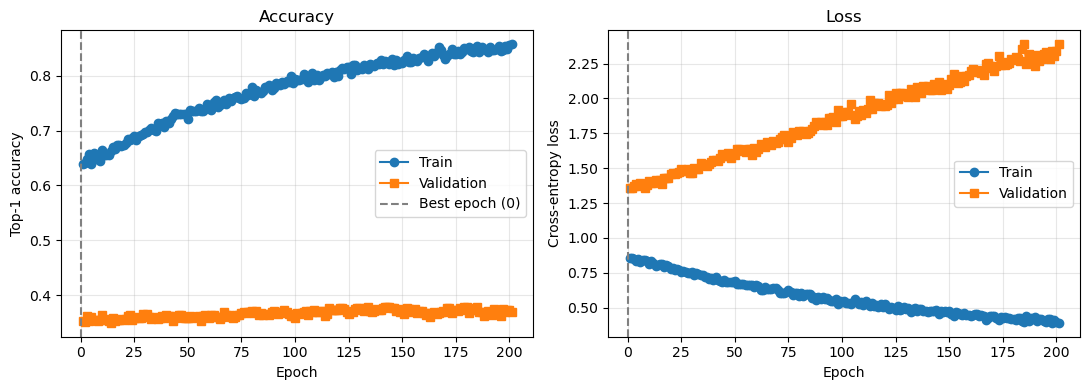

In [91]:
#cell 20
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_acc"]) + 1)
fig, axs = plt.subplots(1, 2, figsize=(11, 4))

axs[0].plot(epochs, history["train_acc"], "-o", label="Train")
axs[0].plot(epochs, history["val_acc"], "-s", label="Validation")
axs[0].axvline(best["epoch"], ls="--", color="gray", label=f"Best epoch ({best['epoch']})")
axs[0].set_xlabel("Epoch"); axs[0].set_ylabel("Top-1 accuracy")
axs[0].set_title("Accuracy"); axs[0].legend(); axs[0].grid(alpha=0.3)

axs[1].plot(epochs, history["train_loss"], "-o", label="Train")
axs[1].plot(epochs, history["val_loss"], "-s", label="Validation")
axs[1].axvline(best["epoch"], ls="--", color="gray")
axs[1].set_xlabel("Epoch"); axs[1].set_ylabel("Cross-entropy loss")
axs[1].set_title("Loss"); axs[1].legend(); axs[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUT_DIR / "training_curves.png", dpi=200)
plt.show()

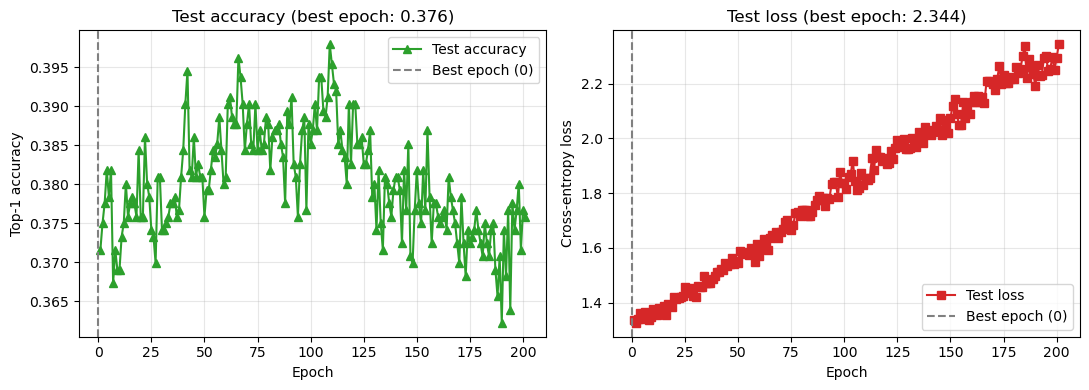

At best epoch 0: test accuracy 0.376 | test loss 2.344


In [93]:
import matplotlib.pyplot as plt
# ---- plot: test accuracy and test loss as line graphs ----
n = len(history["test_acc"]); epochs = range(1, n + 1); b = best["epoch"]
fig, axs = plt.subplots(1, 2, figsize=(11, 4))

axs[0].plot(epochs, history["test_acc"], "-^", color="tab:green", label="Test accuracy")
axs[0].axvline(b, ls="--", color="gray", label=f"Best epoch ({b})")
axs[0].set_xlabel("Epoch"); axs[0].set_ylabel("Top-1 accuracy")
axs[0].set_title(f"Test accuracy (best epoch: {history['test_acc'][b - 1]:.3f})")
axs[0].legend(); axs[0].grid(alpha=0.3)

axs[1].plot(epochs, history["test_loss"], "-s", color="tab:red", label="Test loss")
axs[1].axvline(b, ls="--", color="gray", label=f"Best epoch ({b})")
axs[1].set_xlabel("Epoch"); axs[1].set_ylabel("Cross-entropy loss")
axs[1].set_title(f"Test loss (best epoch: {history['test_loss'][b - 1]:.3f})")
axs[1].legend(); axs[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUT_DIR / "test_accuracy_loss.png", dpi=200)
plt.show()
print(f"At best epoch {b}: test accuracy {history['test_acc'][b - 1]:.3f} | test loss {history['test_loss'][b - 1]:.3f}")